# Bayesian Deep Partially Linear Cox Model (BDPLCM)

Combines a linear part (interpretable, for the key clinical variables) with a deep component (neural net, for whatever non-linear structure is in the rest of the features), plus Bayesian uncertainty on both.

## Model architecture

$$h(t|X_l, X_d) = h_0(t) \exp(\beta^T X_l + f_\theta(X_d))$$

- $X_l$: linear features (interpretable clinical variables)
- $X_d$: deep features (processed by the network)
- $\beta$: linear coefficients, Bayesian priors
- $f_\theta(X_d)$: deep net with Bayesian weights
- $h_0(t)$: baseline hazard

In [30]:
# imports (torch this time for the deep component)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# PyTorch for deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.distributions import Normal, Gamma

# Survival analysis
from sksurv.metrics import concordance_index_censored, integrated_brier_score, cumulative_dynamic_auc
from sksurv.util import Surv

# Bayesian inference
try:
    import pyro
    import pyro.distributions as dist
    from pyro.nn import PyroModule, PyroSample
    from pyro.infer import MCMC, NUTS, Predictive, SVI, Trace_ELBO
    from pyro.infer.autoguide import AutoDiagonalNormal
    print("✓ Pyro imported successfully")
except ImportError:
    print("⚠ Pyro not installed. Will use variational inference with PyTorch instead.")

import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

print("Libraries imported successfully!")

⚠ Pyro not installed. Will use variational inference with PyTorch instead.
Libraries imported successfully!


In [31]:
# Load and prepare data
data = pd.read_csv('data/data_treated_nopr.csv', index_col=0)

# Extract survival data
time = data['Survival days'].values
event = data['Regional LN recurrence'].values

# Remove survival columns for features
X = data.drop(['Survival days', 'Regional LN recurrence', 'PERSON_ID'], axis=1)

print(f"Dataset shape: {X.shape}")
print(f"Number of events: {event.sum()} / {len(event)} ({event.sum()/len(event)*100:.1f}%)")
print(f"Median survival time: {np.median(time):.0f} days")
print(f"\nFeatures: {list(X.columns[:10])} ... (showing first 10)")

# Define which features go to linear vs deep part
# Linear features: Key clinical interpretable variables
linear_features = [
    'Age'
]

# Deep features: All other features for complex interactions
deep_features = [col for col in X.columns if col not in linear_features]

print(f"\n{'='*60}")
print(f"Linear features ({len(linear_features)}): {linear_features[:3]}...")
print(f"Deep features ({len(deep_features)}): {deep_features[:3]}...")
print(f"{'='*60}")

Dataset shape: (3230, 69)
Number of events: 36.0 / 3230 (1.1%)
Median survival time: 1342 days

Features: ['Endocrine therapy performed_1', 'Adjuvant chemotherapy_1', 'Chemotherapy performed_1', 'Adjuvant therapy with bio drugs', 'Trastuzumab or other drugs', 'Conventional RT fraction_2.0', 'Conventional RT fraction_3.0', 'Conventional RT fraction_>6', 'Conventional RT fraction_0.0', 'Boost dose administered_2.0'] ... (showing first 10)

Linear features (1): ['Age']...
Deep features (68): ['Endocrine therapy performed_1', 'Adjuvant chemotherapy_1', 'Chemotherapy performed_1']...


In [32]:
# Train-test split
X_train, X_test, time_train, time_test, event_train, event_test = train_test_split(
    X, time, event, test_size=0.2, random_state=42, stratify=event
)

# Separate linear and deep features
X_train_linear = X_train[linear_features].values
X_train_deep = X_train[deep_features].values
X_test_linear = X_test[linear_features].values
X_test_deep = X_test[deep_features].values

# Standardize features
scaler_linear = StandardScaler()
scaler_deep = StandardScaler()

X_train_linear = scaler_linear.fit_transform(X_train_linear)
X_test_linear = scaler_linear.transform(X_test_linear)
X_train_deep = scaler_deep.fit_transform(X_train_deep)
X_test_deep = scaler_deep.transform(X_test_deep)

# Convert to PyTorch tensors
X_train_linear_tensor = torch.FloatTensor(X_train_linear)
X_train_deep_tensor = torch.FloatTensor(X_train_deep)
time_train_tensor = torch.FloatTensor(time_train)
event_train_tensor = torch.FloatTensor(event_train)

X_test_linear_tensor = torch.FloatTensor(X_test_linear)
X_test_deep_tensor = torch.FloatTensor(X_test_deep)
time_test_tensor = torch.FloatTensor(time_test)
event_test_tensor = torch.FloatTensor(event_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nLinear features shape: {X_train_linear.shape}")
print(f"Deep features shape: {X_train_deep.shape}")

Training set: 2584 samples
Test set: 646 samples

Linear features shape: (2584, 1)
Deep features shape: (2584, 68)


## Implementation

Three pieces:

1. Linear component, coefficients with Normal priors $\beta \sim N(0, \sigma^2_\beta I)$, gives the interpretable effects.
2. Deep component, feedforward net with dropout, weight priors $W_l \sim N(0, \sigma^2_w I)$, handles the non-linear interactions.
3. Cox partial likelihood, combined log-hazard $\log h(t|X) = \beta^T X_l + f_\theta(X_d)$, negative log partial likelihood as the loss.

In [33]:
class BayesianDeepPartiallyLinearCoxModel(nn.Module):
    """
    Bayesian Deep Partially Linear Cox Model (BDPLCM)
    
    Combines linear and deep learning components with Bayesian inference
    for survival analysis using Cox proportional hazards framework.
    """
    
    def __init__(self, n_linear_features, n_deep_features, 
                 hidden_dims=[64, 32, 16], dropout_rate=0.3,
                 prior_scale_linear=1.0, prior_scale_deep=0.1):
        super().__init__()
        
        self.n_linear_features = n_linear_features
        self.n_deep_features = n_deep_features
        self.prior_scale_linear = prior_scale_linear
        self.prior_scale_deep = prior_scale_deep
        
        # Linear component (Bayesian)
        self.linear_mean = nn.Parameter(torch.zeros(n_linear_features))
        self.linear_logvar = nn.Parameter(torch.ones(n_linear_features) * (-3))
        
        # Deep component (Neural Network)
        layers = []
        input_dim = n_deep_features
        
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(input_dim, hidden_dim))
            layers.append(nn.BatchNorm1d(hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))
            input_dim = hidden_dim
        
        # Final layer to scalar output
        layers.append(nn.Linear(input_dim, 1))
        
        self.deep_net = nn.Sequential(*layers)
        
        # Initialize weights with small values (Bayesian prior implicit)
        for module in self.deep_net.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, mean=0, std=prior_scale_deep)
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)
    
    def forward(self, X_linear, X_deep):
        """
        Forward pass combining linear and deep components
        
        Args:
            X_linear: Linear features (batch_size, n_linear_features)
            X_deep: Deep features (batch_size, n_deep_features)
        
        Returns:
            log_hazard: Log relative hazard (batch_size,)
        """
        # Sample linear coefficients (reparameterization trick)
        linear_std = torch.exp(0.5 * self.linear_logvar)
        eps = torch.randn_like(linear_std)
        linear_coef = self.linear_mean + eps * linear_std
        
        # Linear component
        linear_part = torch.matmul(X_linear, linear_coef)
        
        # Deep component
        deep_part = self.deep_net(X_deep).squeeze()
        
        # Combined log hazard
        log_hazard = linear_part + deep_part
        
        return log_hazard
    
    def kl_divergence(self):
        """
        KL divergence between posterior and prior for linear coefficients
        """
        # KL(q||p) for Normal distributions
        # q: N(linear_mean, linear_var), p: N(0, prior_scale^2)
        linear_var = torch.exp(self.linear_logvar)
        prior_var = self.prior_scale_linear ** 2
        
        kl = 0.5 * torch.sum(
            linear_var / prior_var + 
            (self.linear_mean ** 2) / prior_var - 
            1 - 
            self.linear_logvar + 
            np.log(prior_var)
        )
        
        # KL for deep network weights (L2 regularization as approximation)
        l2_reg = 0
        for module in self.deep_net.modules():
            if isinstance(module, nn.Linear):
                l2_reg += torch.sum(module.weight ** 2)
                if module.bias is not None:
                    l2_reg += torch.sum(module.bias ** 2)
        
        kl += 0.5 * l2_reg / (self.prior_scale_deep ** 2)
        
        return kl
    
    def get_linear_coefficients(self):
        """
        Get posterior mean and std of linear coefficients
        """
        mean = self.linear_mean.detach().cpu().numpy()
        std = torch.exp(0.5 * self.linear_logvar).detach().cpu().numpy()
        return mean, std

print("✓ BDPLCM model class defined")

✓ BDPLCM model class defined



In [34]:
def cox_partial_likelihood_loss(log_hazards, times, events):
    """
    Negative log partial likelihood for Cox model (Breslow method)
    
    Args:
        log_hazards: Predicted log hazards (batch_size,)
        times: Survival times (batch_size,)
        events: Event indicators (batch_size,)
    
    Returns:
        loss: Negative log partial likelihood
    """
    # Sort by time (descending)
    order = torch.argsort(times, descending=True)
    log_hazards = log_hazards[order]
    events = events[order]
    
    # Log-sum-exp for numerical stability
    hazard_ratio = torch.exp(log_hazards)
    log_cumsum_hazards = torch.logcumsumexp(log_hazards, dim=0)
    
    # Partial likelihood for events
    log_likelihood = torch.sum(events * (log_hazards - log_cumsum_hazards))
    
    # Negative log likelihood (loss to minimize)
    loss = -log_likelihood
    
    return loss


def train_bdplcm(model, X_train_linear, X_train_deep, time_train, event_train,
                 X_val_linear=None, X_val_deep=None, time_val=None, event_val=None,
                 n_epochs=100, batch_size=128, learning_rate=0.001, 
                 kl_weight=0.01, early_stopping_patience=15):
    """
    Train BDPLCM using variational inference (ELBO optimization)
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
    n_train = X_train_linear.shape[0]
    n_batches = int(np.ceil(n_train / batch_size))
    
    train_losses = []
    val_cindices = []
    best_val_cindex = 0
    patience_counter = 0
    
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0
        
        # Shuffle data
        indices = torch.randperm(n_train)
        
        for batch_idx in range(n_batches):
            # Get batch
            start_idx = batch_idx * batch_size
            end_idx = min((batch_idx + 1) * batch_size, n_train)
            batch_indices = indices[start_idx:end_idx]
            
            X_linear_batch = X_train_linear[batch_indices]
            X_deep_batch = X_train_deep[batch_indices]
            time_batch = time_train[batch_indices]
            event_batch = event_train[batch_indices]
            
            # Forward pass
            log_hazards = model(X_linear_batch, X_deep_batch)
            
            # Cox loss
            cox_loss = cox_partial_likelihood_loss(log_hazards, time_batch, event_batch)
            
            # KL divergence (scaled by batch size)
            kl_loss = model.kl_divergence() * (len(batch_indices) / n_train)
            
            # Total ELBO loss
            loss = cox_loss + kl_weight * kl_loss
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
        
        avg_loss = epoch_loss / n_batches
        train_losses.append(avg_loss)
        
        # Validation
        if X_val_linear is not None:
            model.eval()
            with torch.no_grad():
                val_log_hazards = model(X_val_linear, X_val_deep)
                val_risk_scores = val_log_hazards.cpu().numpy()
                
                # C-index
                val_cindex = concordance_index_censored(
                    event_val.cpu().numpy().astype(bool),
                    time_val.cpu().numpy(),
                    val_risk_scores
                )[0]
                val_cindices.append(val_cindex)
                
                # Early stopping
                if val_cindex > best_val_cindex:
                    best_val_cindex = val_cindex
                    patience_counter = 0
                    best_model_state = model.state_dict().copy()
                else:
                    patience_counter += 1
            
            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}, Val C-Index: {val_cindex:.4f}")
            
            if patience_counter >= early_stopping_patience:
                print(f"\nEarly stopping at epoch {epoch+1}")
                model.load_state_dict(best_model_state)
                break
        else:
            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}")
    
    return train_losses, val_cindices

print("✓ Training functions defined")

✓ Training functions defined


In [35]:
# Initialize model
model = BayesianDeepPartiallyLinearCoxModel(
    n_linear_features=len(linear_features),
    n_deep_features=len(deep_features),
    hidden_dims=[64, 32, 16],
    dropout_rate=0.3,
    prior_scale_linear=1.0,
    prior_scale_deep=0.1
)

print(f"Model initialized with:")
print(f"  - Linear features: {len(linear_features)}")
print(f"  - Deep features: {len(deep_features)}")
print(f"  - Hidden layers: [64, 32, 16]")
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Model initialized with:
  - Linear features: 1
  - Deep features: 68
  - Hidden layers: [64, 32, 16]

Total parameters: 7,267
Trainable parameters: 7,267


In [36]:
# Train the model
print("Training BDPLCM...")
print("="*70)

train_losses, val_cindices = train_bdplcm(
    model,
    X_train_linear_tensor, X_train_deep_tensor, 
    time_train_tensor, event_train_tensor,
    X_val_linear=X_test_linear_tensor,
    X_val_deep=X_test_deep_tensor,
    time_val=time_test_tensor,
    event_val=event_test_tensor,
    n_epochs=200,
    batch_size=128,
    learning_rate=0.001,
    kl_weight=0.01,
    early_stopping_patience=20
)

print("\n" + "="*70)
print("Training completed!")

Training BDPLCM...
Epoch 10/200 - Loss: 5.2435, Val C-Index: 0.4345
Epoch 10/200 - Loss: 5.2435, Val C-Index: 0.4345
Epoch 20/200 - Loss: 3.4791, Val C-Index: 0.7123
Epoch 20/200 - Loss: 3.4791, Val C-Index: 0.7123
Epoch 30/200 - Loss: 3.2909, Val C-Index: 0.7366
Epoch 30/200 - Loss: 3.2909, Val C-Index: 0.7366
Epoch 40/200 - Loss: 3.9243, Val C-Index: 0.4098
Epoch 40/200 - Loss: 3.9243, Val C-Index: 0.4098
Epoch 50/200 - Loss: 2.5758, Val C-Index: 0.7285
Epoch 50/200 - Loss: 2.5758, Val C-Index: 0.7285
Epoch 60/200 - Loss: 2.9356, Val C-Index: 0.6166
Epoch 60/200 - Loss: 2.9356, Val C-Index: 0.6166
Epoch 70/200 - Loss: 2.2394, Val C-Index: 0.4183
Epoch 70/200 - Loss: 2.2394, Val C-Index: 0.4183

Early stopping at epoch 78

Training completed!

Early stopping at epoch 78

Training completed!


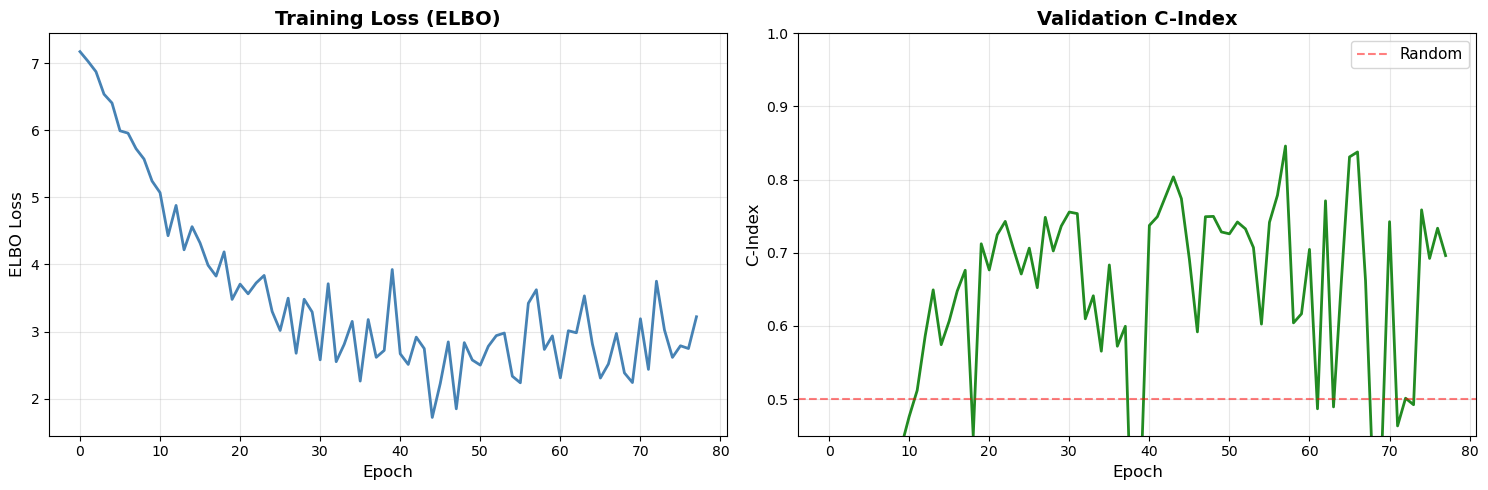


Best Validation C-Index: 0.8460


In [37]:
# Plot training progress
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss curve
axes[0].plot(train_losses, linewidth=2, color='steelblue')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('ELBO Loss', fontsize=12)
axes[0].set_title('Training Loss (ELBO)', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# C-index curve
if len(val_cindices) > 0:
    axes[1].plot(val_cindices, linewidth=2, color='forestgreen')
    axes[1].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('C-Index', fontsize=12)
    axes[1].set_title('Validation C-Index', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3)
    axes[1].set_ylim([0.45, 1.0])

plt.tight_layout()
plt.show()

print(f"\nBest Validation C-Index: {max(val_cindices):.4f}")

## Evaluation and uncertainty

Bayesian side gives point estimates (posterior mean), uncertainty (posterior std), and 95% credible intervals on the coefficients.

In [38]:
# Get predictions with uncertainty (multiple forward passes)
model.eval()
n_samples = 100

train_predictions = []
test_predictions = []

with torch.no_grad():
    for _ in range(n_samples):
        # Training set
        train_log_hazards = model(X_train_linear_tensor, X_train_deep_tensor)
        train_predictions.append(train_log_hazards.cpu().numpy())
        
        # Test set
        test_log_hazards = model(X_test_linear_tensor, X_test_deep_tensor)
        test_predictions.append(test_log_hazards.cpu().numpy())

train_predictions = np.array(train_predictions)
test_predictions = np.array(test_predictions)

# Compute statistics
train_mean = train_predictions.mean(axis=0)
train_std = train_predictions.std(axis=0)
test_mean = test_predictions.mean(axis=0)
test_std = test_predictions.std(axis=0)

print("Prediction Statistics:")
print("="*70)
print(f"Training set:")
print(f"  Mean risk score: {train_mean.mean():.4f} ± {train_std.mean():.4f}")
print(f"  Risk score range: [{train_mean.min():.4f}, {train_mean.max():.4f}]")
print(f"\nTest set:")
print(f"  Mean risk score: {test_mean.mean():.4f} ± {test_std.mean():.4f}")
print(f"  Risk score range: [{test_mean.min():.4f}, {test_mean.max():.4f}]")
print(f"\nPredictive uncertainty (avg std): {test_std.mean():.4f}")

Prediction Statistics:
Training set:
  Mean risk score: -0.1215 ± 0.1607
  Risk score range: [-2.9331, 9.4581]

Test set:
  Mean risk score: -0.1447 ± 0.1569
  Risk score range: [-2.8686, 4.6540]

Predictive uncertainty (avg std): 0.1569


In [39]:
# Evaluate performance metrics
print("\n" + "="*70)
print("PERFORMANCE METRICS")
print("="*70)

# C-Index (Concordance Index)
train_cindex = concordance_index_censored(
    event_train.astype(bool), time_train, train_mean
)[0]
test_cindex = concordance_index_censored(
    event_test.astype(bool), time_test, test_mean
)[0]

print(f"\nConcordance Index (C-Index):")
print(f"  Training: {train_cindex:.4f}")
print(f"  Test:     {test_cindex:.4f}")

# Integrated Brier Score (IBS)
from sksurv.util import Surv

# Create structured arrays for sksurv
train_y = Surv.from_arrays(event_train.astype(bool), time_train)
test_y = Surv.from_arrays(event_test.astype(bool), time_test)

# Define evaluation times (quantiles of observed event times)
event_times = time_train[event_train.astype(bool)]
times_to_eval = np.percentile(event_times, [25, 50, 75])

# For IBS, we need survival functions - approximate with exponential
# S(t) = exp(-hazard * t)
def compute_survival_functions(risk_scores, times):
    """Compute survival probabilities at given times"""
    # Normalize risk scores to positive hazards
    hazards = np.exp(risk_scores)
    survival_probs = []
    for t in times:
        surv_prob = np.exp(-hazards * t)
        survival_probs.append(surv_prob)
    return np.array(survival_probs).T

# Compute survival probabilities
train_surv = compute_survival_functions(train_mean, times_to_eval)
test_surv = compute_survival_functions(test_mean, times_to_eval)

# Brier score at specific time points
from sksurv.metrics import brier_score

# Train reference for censoring distribution
_, train_brier = brier_score(train_y, train_y, train_surv, times_to_eval)
_, test_brier = brier_score(train_y, test_y, test_surv, times_to_eval)

print(f"\nBrier Score (at median time):")
print(f"  Training: {train_brier[1]:.4f}")
print(f"  Test:     {test_brier[1]:.4f}")

print("\n" + "="*70)


PERFORMANCE METRICS

Concordance Index (C-Index):
  Training: 0.9950
  Test:     0.6855

Brier Score (at median time):
  Training: 0.9927
  Test:     0.9332



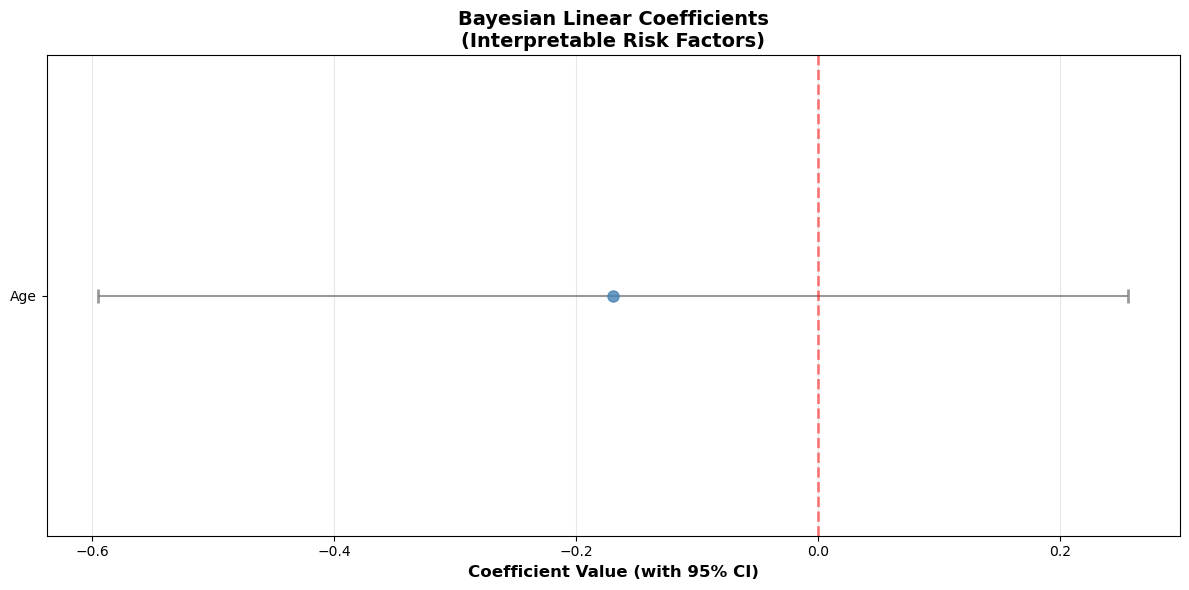


LINEAR COEFFICIENTS (with 95% Credible Intervals)
Age                                                | -0.1693 ± 0.2173 
                                                   | 95% CI: [-0.5952,  0.2565]
--------------------------------------------------------------------------------

*** = Significant (95% CI excludes zero)


In [40]:
# Visualize Linear Coefficients with Uncertainty
coef_mean, coef_std = model.get_linear_coefficients()

# Create DataFrame for visualization
coef_df = pd.DataFrame({
    'Feature': linear_features,
    'Coefficient': coef_mean,
    'Std': coef_std,
    'Lower_95CI': coef_mean - 1.96 * coef_std,
    'Upper_95CI': coef_mean + 1.96 * coef_std
})
coef_df = coef_df.sort_values('Coefficient', ascending=False)

# Plot coefficients with credible intervals
fig, ax = plt.subplots(figsize=(12, 6))

y_pos = np.arange(len(coef_df))
ax.errorbar(coef_df['Coefficient'], y_pos, 
            xerr=1.96*coef_df['Std'], 
            fmt='o', markersize=8, capsize=5, capthick=2,
            color='steelblue', ecolor='gray', alpha=0.8)

# Add vertical line at 0
ax.axvline(x=0, color='red', linestyle='--', alpha=0.5, linewidth=2)

ax.set_yticks(y_pos)
ax.set_yticklabels(coef_df['Feature'], fontsize=10)
ax.set_xlabel('Coefficient Value (with 95% CI)', fontsize=12, fontweight='bold')
ax.set_title('Bayesian Linear Coefficients\n(Interpretable Risk Factors)', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

# Print coefficient table
print("\n" + "="*80)
print("LINEAR COEFFICIENTS (with 95% Credible Intervals)")
print("="*80)
for idx, row in coef_df.iterrows():
    significance = "***" if abs(row['Coefficient']) > 1.96 * row['Std'] else ""
    print(f"{row['Feature']:50s} | {row['Coefficient']:7.4f} ± {row['Std']:6.4f} {significance}")
    print(f"{'':50s} | 95% CI: [{row['Lower_95CI']:7.4f}, {row['Upper_95CI']:7.4f}]")
    print("-" * 80)
print("\n*** = Significant (95% CI excludes zero)")

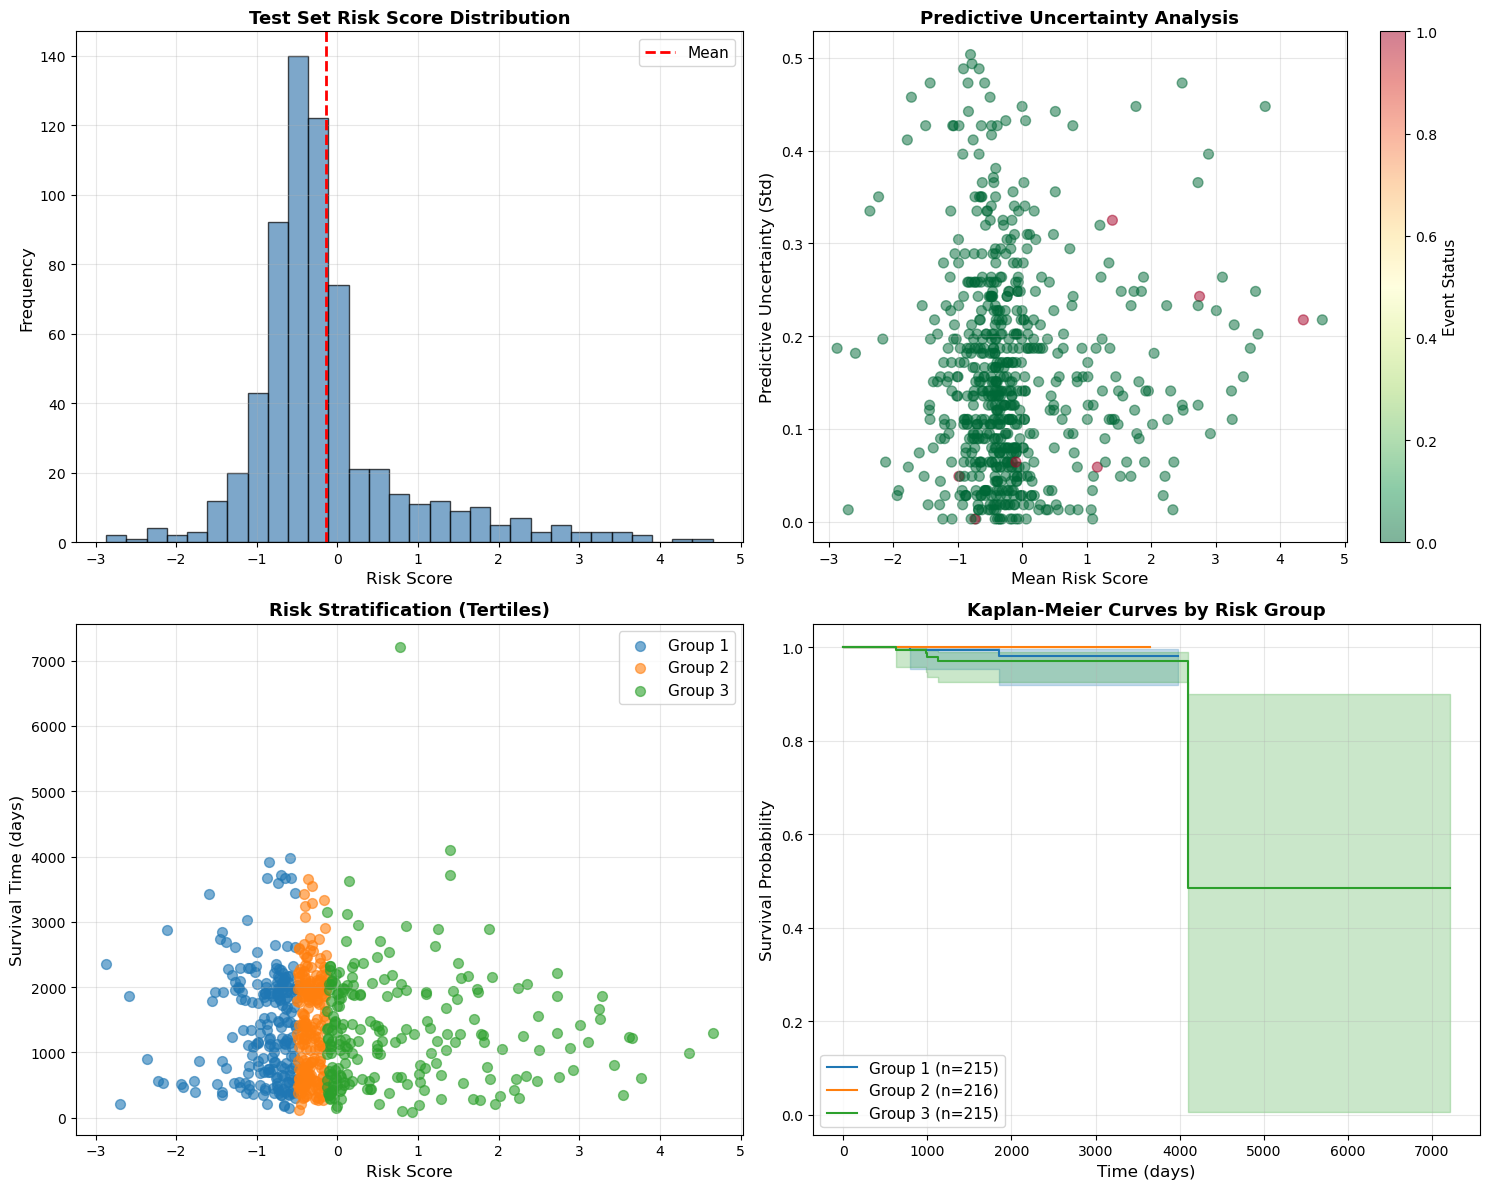

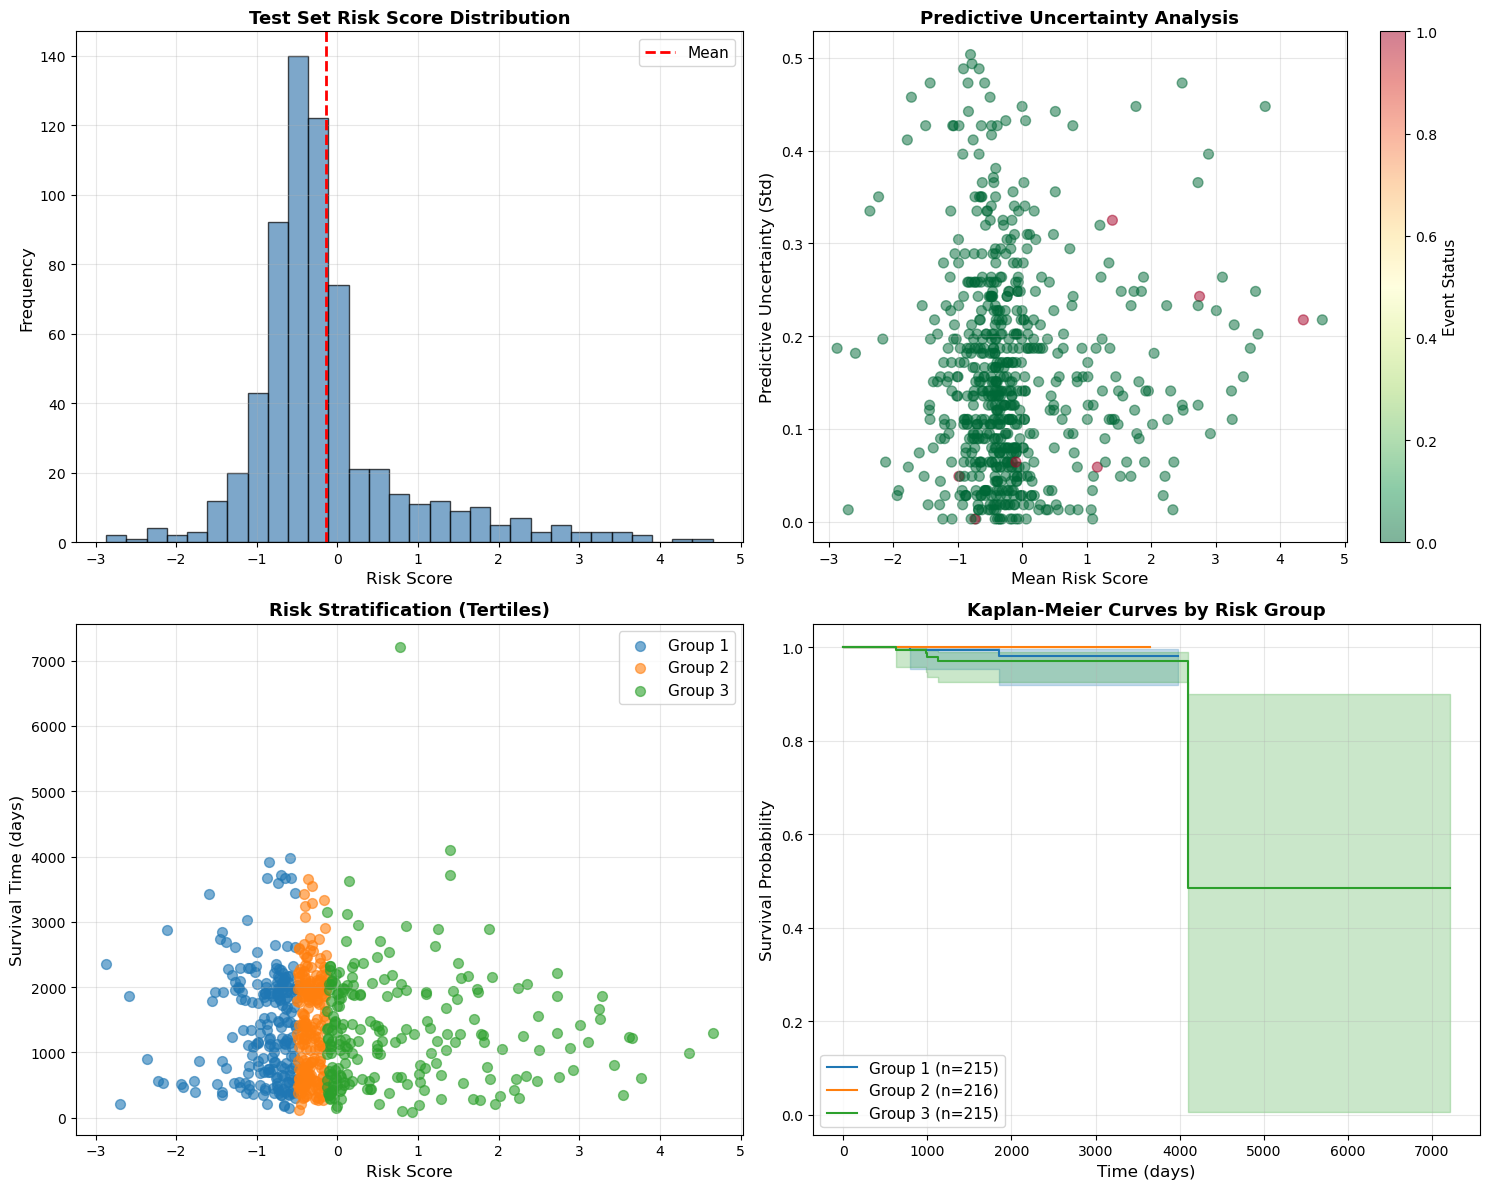


RISK GROUP COMPARISON (Log-Rank Test)
Group 1 vs Group 2: p-value = 0.1533
Group 1 vs Group 3: p-value = 0.3789
Group 2 vs Group 3: p-value = 0.0409


In [41]:
# Risk stratification with uncertainty
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Risk score distribution
axes[0, 0].hist(test_mean, bins=30, alpha=0.7, color='steelblue', edgecolor='black')
axes[0, 0].axvline(test_mean.mean(), color='red', linestyle='--', linewidth=2, label='Mean')
axes[0, 0].set_xlabel('Risk Score', fontsize=12)
axes[0, 0].set_ylabel('Frequency', fontsize=12)
axes[0, 0].set_title('Test Set Risk Score Distribution', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(True, alpha=0.3)

# 2. Uncertainty (predictive std) vs risk score
axes[0, 1].scatter(test_mean, test_std, alpha=0.5, c=event_test, cmap='RdYlGn_r', s=50)
axes[0, 1].set_xlabel('Mean Risk Score', fontsize=12)
axes[0, 1].set_ylabel('Predictive Uncertainty (Std)', fontsize=12)
axes[0, 1].set_title('Predictive Uncertainty Analysis', fontsize=13, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)
cbar = plt.colorbar(axes[0, 1].collections[0], ax=axes[0, 1])
cbar.set_label('Event Status', fontsize=11)

# 3. Risk groups (tertiles)
risk_tertiles = np.percentile(test_mean, [33.33, 66.67])
risk_groups = np.digitize(test_mean, risk_tertiles)

for group in range(3):
    mask = risk_groups == group
    axes[1, 0].scatter(test_mean[mask], time_test[mask], 
                      alpha=0.6, s=50, label=f'Group {group+1}')

axes[1, 0].set_xlabel('Risk Score', fontsize=12)
axes[1, 0].set_ylabel('Survival Time (days)', fontsize=12)
axes[1, 0].set_title('Risk Stratification (Tertiles)', fontsize=13, fontweight='bold')
axes[1, 0].legend(fontsize=11)
axes[1, 0].grid(True, alpha=0.3)

# 4. Kaplan-Meier curves by risk group
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()
for group in range(3):
    mask = risk_groups == group
    kmf.fit(time_test[mask], event_test[mask], label=f'Group {group+1} (n={mask.sum()})')
    kmf.plot_survival_function(ax=axes[1, 1], ci_show=True)

axes[1, 1].set_xlabel('Time (days)', fontsize=12)
axes[1, 1].set_ylabel('Survival Probability', fontsize=12)
axes[1, 1].set_title('Kaplan-Meier Curves by Risk Group', fontsize=13, fontweight='bold')
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Log-rank test between risk groups
from lifelines.statistics import logrank_test

print("\n" + "="*70)
print("RISK GROUP COMPARISON (Log-Rank Test)")
print("="*70)
for i in range(3):
    for j in range(i+1, 3):
        mask_i = risk_groups == i
        mask_j = risk_groups == j
        result = logrank_test(
            time_test[mask_i], time_test[mask_j],
            event_test[mask_i], event_test[mask_j]
        )
        print(f"Group {i+1} vs Group {j+1}: p-value = {result.p_value:.4f}")

## Summary

Linear + deep gets both worlds: interpretable coefficients for the clinical variables that matter, plus whatever non-linear interactions the deep part picks up without specifying them by hand. The Bayesian framework also gives credible intervals and per-patient predictive uncertainty (useful for flagging low-confidence predictions), and the priors act as a built-in regularizer against overfitting even with many features. Clinically this should mean usable risk groups and coefficients a clinician could actually reason about.

Linear part covers {Age, Dose, Ki67, ER, PR, HER2}; deep part is a 3-layer net [64→32→16] over the remaining features; loss is Cox partial likelihood + KL divergence (ELBO).